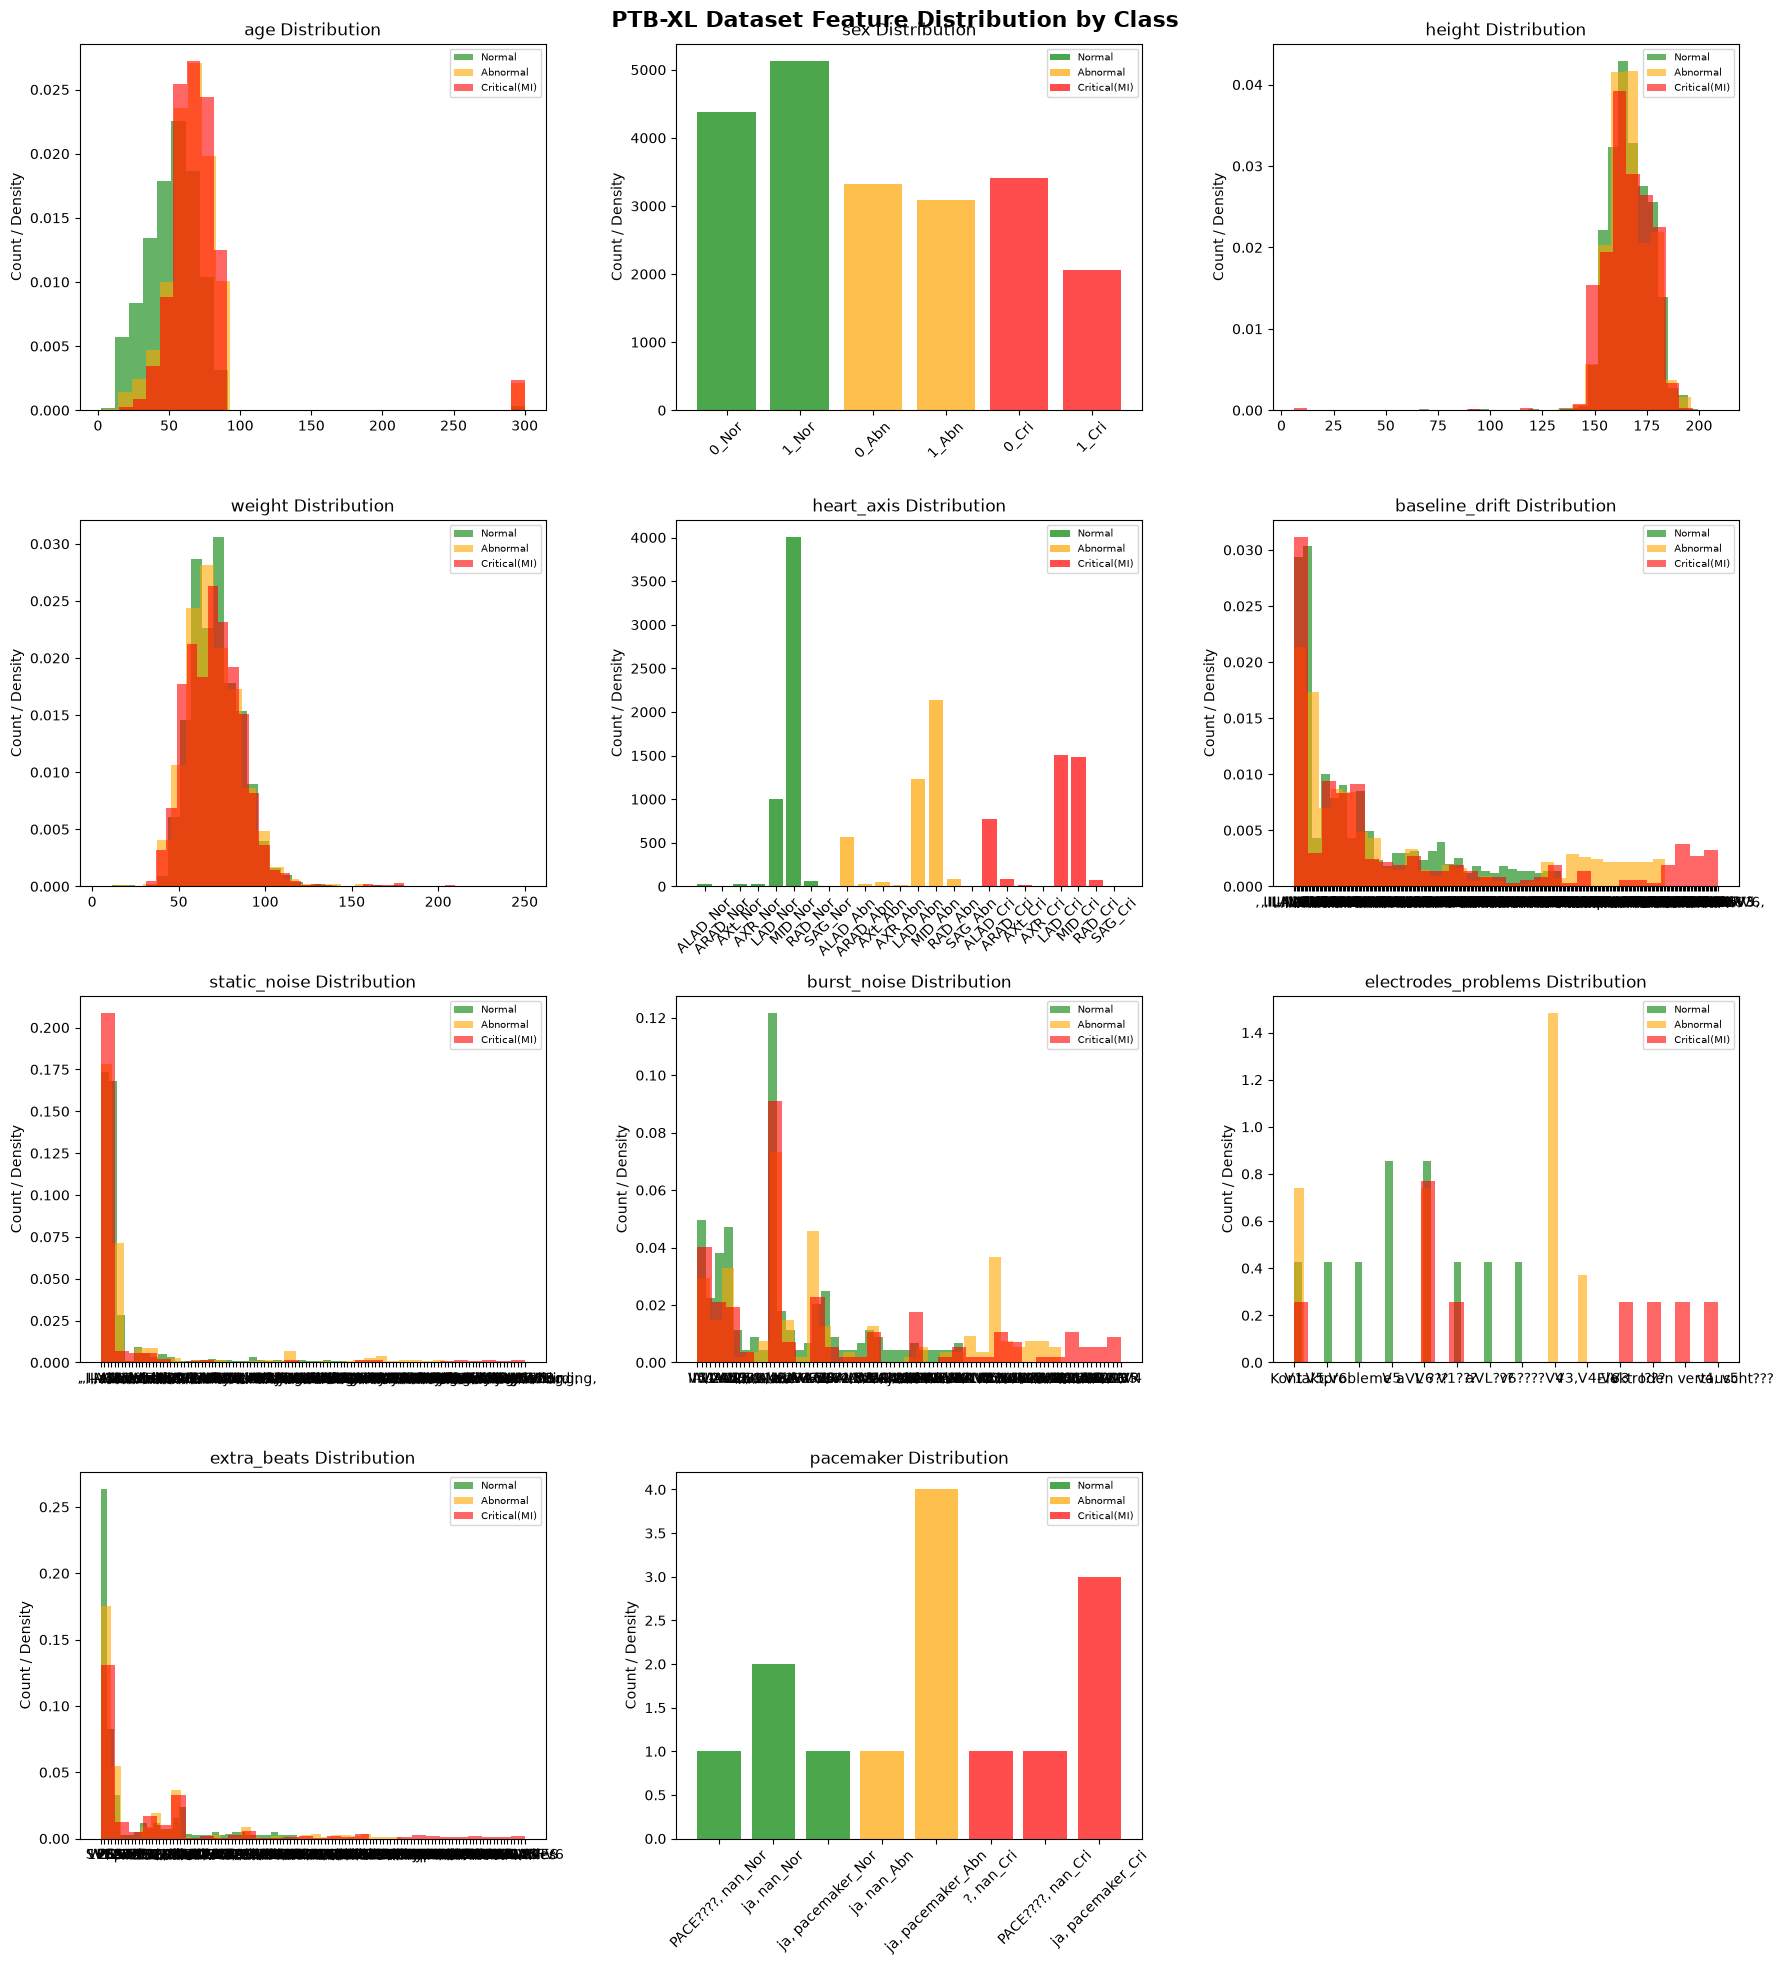

In [2]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
import ast

PATH = './ptbxl/ptb-xl-a-large-publicly-available-electrocardiography-dataset-1.0.3/'

# reload data
df = pd.read_csv(PATH + 'ptbxl_database.csv')
scp_df = pd.read_csv(PATH + 'scp_statements.csv', index_col=0)
df['scp_codes'] = df['scp_codes'].apply(ast.literal_eval)

def get_superclass(scp_dict):
    superclasses = []
    for code in scp_dict.keys():
        if code in scp_df.index:
            sc = scp_df.loc[code, 'diagnostic_class']
            if pd.notna(sc):
                superclasses.append(sc)
    return list(set(superclasses)) if superclasses else ['UNKNOWN']

df['superclass'] = df['scp_codes'].apply(get_superclass)

def map_label(superclasses):
    if 'MI' in superclasses:
        return 2
    elif 'NORM' in superclasses:
        return 0
    elif 'UNKNOWN' in superclasses:
        return -1
    else:
        return 1

df['label'] = df['superclass'].apply(map_label)
df = df[df['label'] != -1].reset_index(drop=True)

label_names = {0: 'Normal', 1: 'Abnormal', 2: 'Critical(MI)'}
df['label_name'] = df['label'].map(label_names)

# plot
plot_cols = ['age', 'sex', 'height', 'weight', 'heart_axis',
             'baseline_drift', 'static_noise', 'burst_noise',
             'electrodes_problems', 'extra_beats', 'pacemaker']

colors = ['green', 'orange', 'red']
classes = ['Normal', 'Abnormal', 'Critical(MI)']

fig, axes = plt.subplots(4, 3, figsize=(18, 20))
axes = axes.flatten()

for idx, col in enumerate(plot_cols):
    ax = axes[idx]

    if df[col].nunique() <= 10:  # categorical
        for i, cls in enumerate(classes):
            subset = df[df['label_name'] == cls][col].value_counts().sort_index()
            ax.bar([str(x) + f'_{cls[:3]}' for x in subset.index],
                   subset.values, color=colors[i], alpha=0.7, label=cls)
        ax.set_title(f'{col} Distribution')
        ax.legend(fontsize=7)
        ax.tick_params(axis='x', rotation=45)

    else:  # continuous
        for i, cls in enumerate(classes):
            subset = df[df['label_name'] == cls][col].dropna()
            ax.hist(subset, bins=30, color=colors[i],
                    alpha=0.6, label=cls, density=True)
        ax.set_title(f'{col} Distribution')
        ax.legend(fontsize=7)

    ax.set_ylabel('Count / Density')

axes[-1].set_visible(False)

plt.suptitle('PTB-XL Dataset Feature Distribution by Class',
             fontsize=16, fontweight='bold')
plt.tight_layout()
plt.savefig('feature_distributions.png', dpi=150, bbox_inches='tight')
plt.show()

In [4]:
print("Age statistics:")
print(df['age'].describe())
print("\nAge > 120 (invalid):")
print(df[df['age'] > 120][['age', 'label_name']].value_counts())
print("\nTotal invalid age records:", len(df[df['age'] > 120]))
print(df.describe())

Age statistics:
count    21388.000000
mean        62.608753
std         32.235489
min          2.000000
25%         50.000000
50%         62.000000
75%         72.000000
max        300.000000
Name: age, dtype: float64

Age > 120 (invalid):
age    label_name  
300.0  Abnormal        133
       Critical(MI)    121
       Normal           31
Name: count, dtype: int64

Total invalid age records: 285
             ecg_id    patient_id           age           sex       height  \
count  21388.000000  21388.000000  21388.000000  21388.000000  6918.000000   
mean   10891.272115  11210.154432     62.608753      0.480503   166.694565   
std     6300.265743   6240.997937     32.235489      0.499631    10.869989   
min        1.000000    302.000000      2.000000      0.000000     6.000000   
25%     5431.750000   5915.750000     50.000000      0.000000   160.000000   
50%    10862.500000  11360.500000     62.000000      0.000000   166.000000   
75%    16349.250000  16568.250000     72.000000      1.

Removed: 285 records
Remaining: 21103


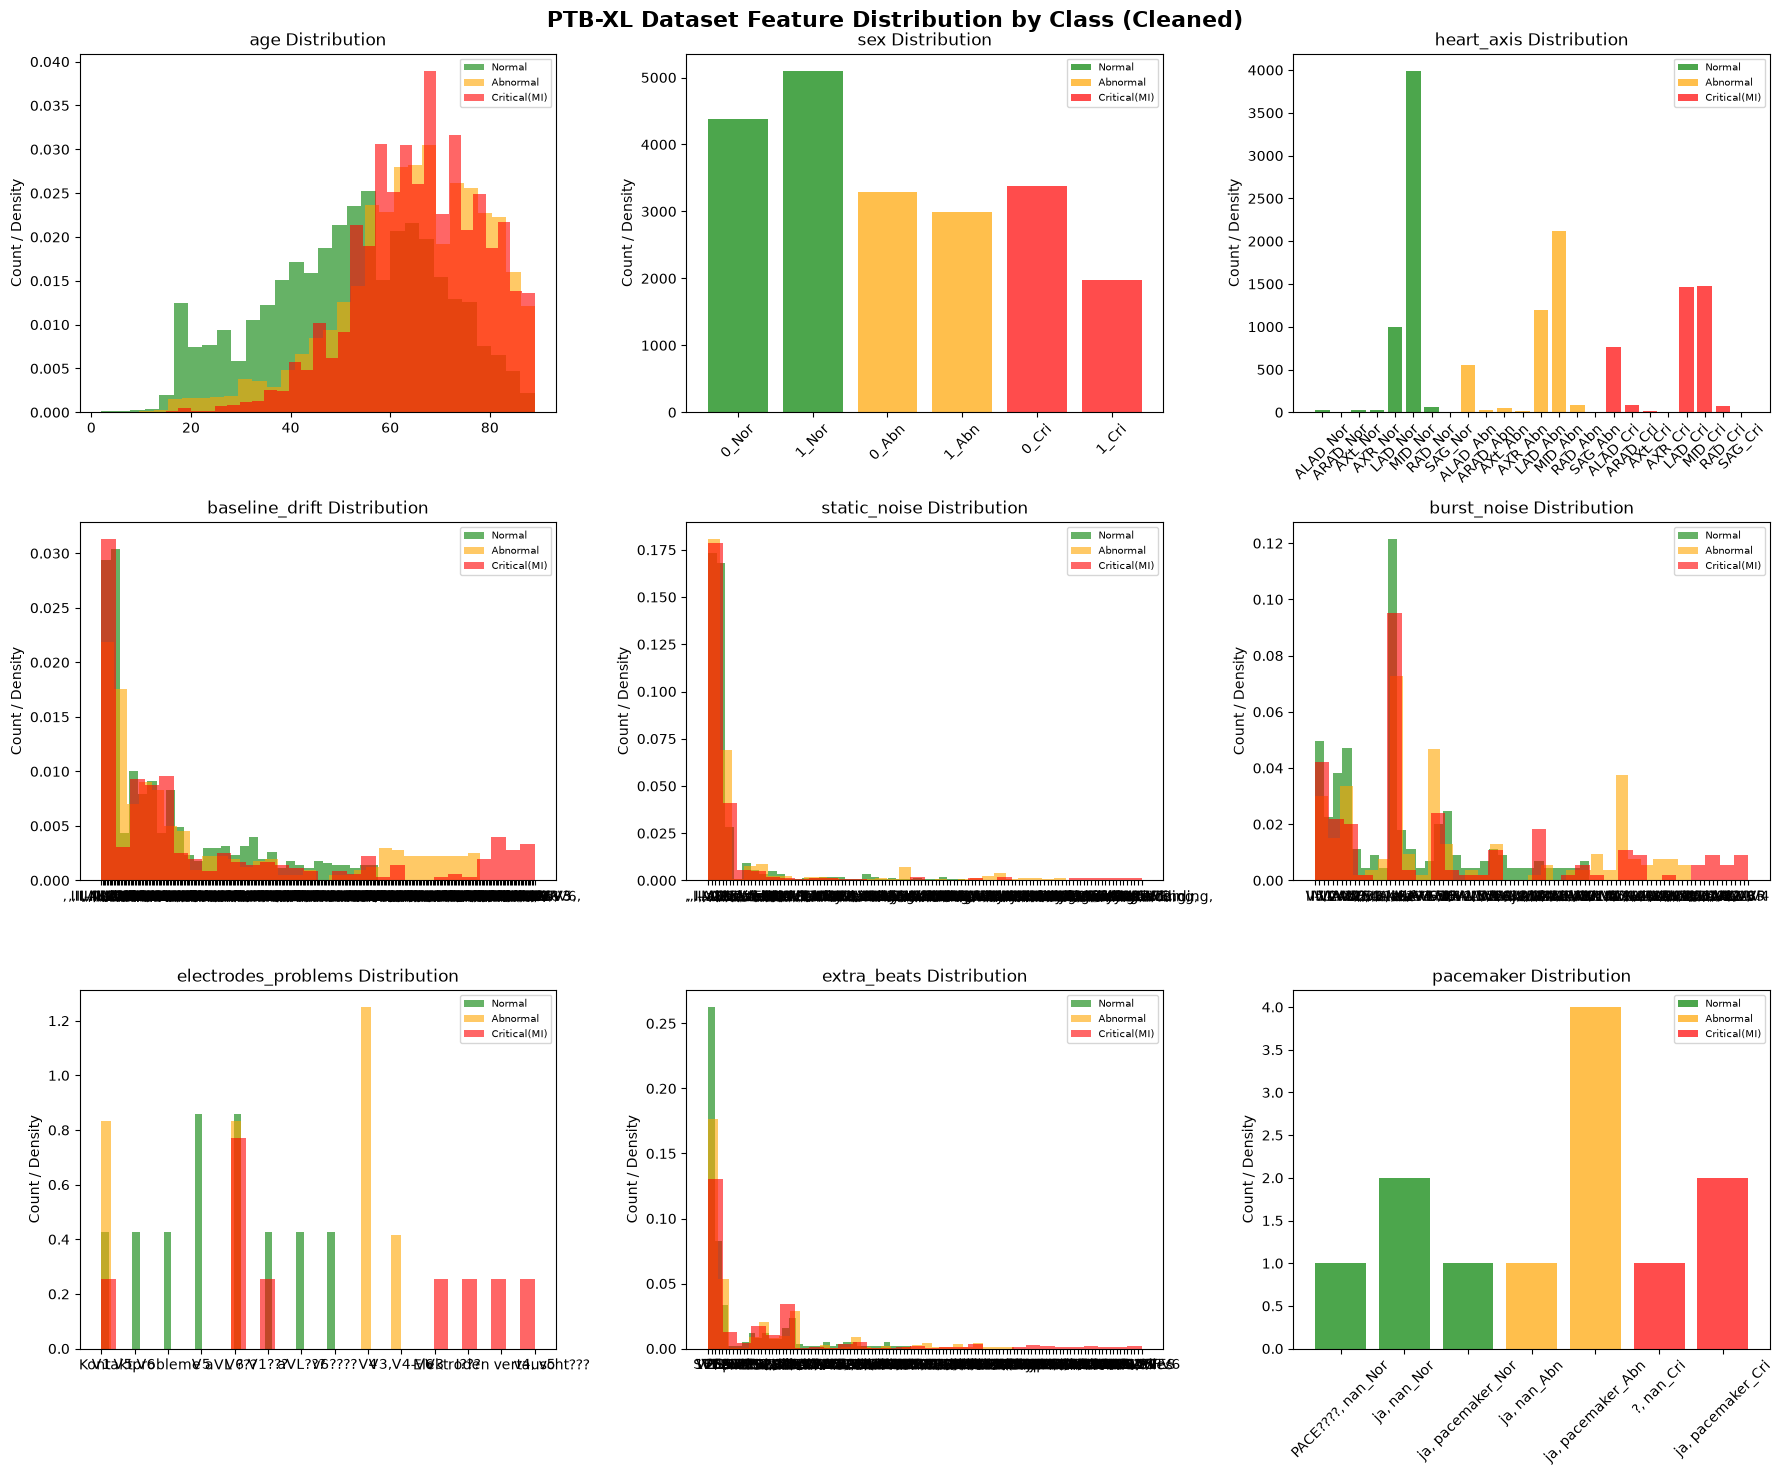

In [5]:
# clean invalid ages
df_clean = df[df['age'] <= 120].copy()
print("Removed:", len(df) - len(df_clean), "records")
print("Remaining:", len(df_clean))

# replot with clean data, drop height and weight
plot_cols = ['age', 'sex', 'heart_axis', 'baseline_drift', 
             'static_noise', 'burst_noise', 'electrodes_problems', 
             'extra_beats', 'pacemaker']

colors = ['green', 'orange', 'red']
classes = ['Normal', 'Abnormal', 'Critical(MI)']

fig, axes = plt.subplots(3, 3, figsize=(18, 15))
axes = axes.flatten()

for idx, col in enumerate(plot_cols):
    ax = axes[idx]
    if df_clean[col].nunique() <= 10:
        for i, cls in enumerate(classes):
            subset = df_clean[df_clean['label_name'] == cls][col].value_counts().sort_index()
            ax.bar([str(x) + f'_{cls[:3]}' for x in subset.index],
                   subset.values, color=colors[i], alpha=0.7, label=cls)
        ax.set_title(f'{col} Distribution')
        ax.legend(fontsize=7)
        ax.tick_params(axis='x', rotation=45)
    else:
        for i, cls in enumerate(classes):
            subset = df_clean[df_clean['label_name'] == cls][col].dropna()
            ax.hist(subset, bins=30, color=colors[i],
                    alpha=0.6, label=cls, density=True)
        ax.set_title(f'{col} Distribution')
        ax.legend(fontsize=7)
    ax.set_ylabel('Count / Density')

plt.suptitle('PTB-XL Dataset Feature Distribution by Class (Cleaned)',
             fontsize=16, fontweight='bold')
plt.tight_layout()
plt.savefig('feature_distributions_clean.png', dpi=150, bbox_inches='tight')
plt.show()